# CodeGraph-RAG / PathPack v0.2

**Исследовательский ноутбук, 1 ноября 2026**

Здесь воспроизводится первый прототип поиска зависимостей и сравнение с BM25. Данные ниже **искусственные**, потому что реальные репозитории SWE-bench ещё не скачаны. Эти диаграммы нельзя использовать как доказательство качества на SWE-bench.

Цель следующего этапа: оценить реальную локализацию ошибок на снимках Git из SWE-bench Verified, строго до исправления.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "Запустите ноутбук из папки проекта"
sys.path.insert(0, str(ROOT / "src"))
from codegraph_rag.parser import scan_repository
from codegraph_rag.retrieval import retrieve, make_chunks, select_context
print('Project root:', ROOT)

Project root: /mnt/data/CodeGraph-RAG-v0.2


## 1. Строим статический граф Python

Узлы: модули и функции. Рёбра: импорты, определения, вызовы. Анализ выполняется без запуска анализируемого кода. Динамические вызовы могут быть пропущены.

In [2]:
repo = ROOT / "examples/issue_demo/snapshot"
graph = scan_repository(repo)
print(json.dumps(graph.stats(), ensure_ascii=False, indent=2))
print("Примеры связей вызова:")
for e in sorted(graph.edges, key=lambda x: (x.source,x.target)):
    if e.kind == 'calls': print(' ',e.source, '->', e.target)

{
  "nodes": 20,
  "edges": 23,
  "symbols": {
    "function": 11,
    "module": 9
  },
  "relations": {
    "calls": 4,
    "defines": 11,
    "imports": 8
  },
  "parse_errors": {}
}
Примеры связей вызова:
  auth.py::login_with_cookie -> store.py::read_session
  invoice.py::checkout_invoice -> taxes.py::compute_tax
  notifications.py::send_notification -> packets.py::encode_packet
  uploads.py::upload_image -> filesys.py::write_blob


## 2. Визуализируем фрагмент графа

Бирюзовые узлы показывают релевантную цепочку по одной задаче, серый узел показывает похожую по названию, но не связанную функцию.

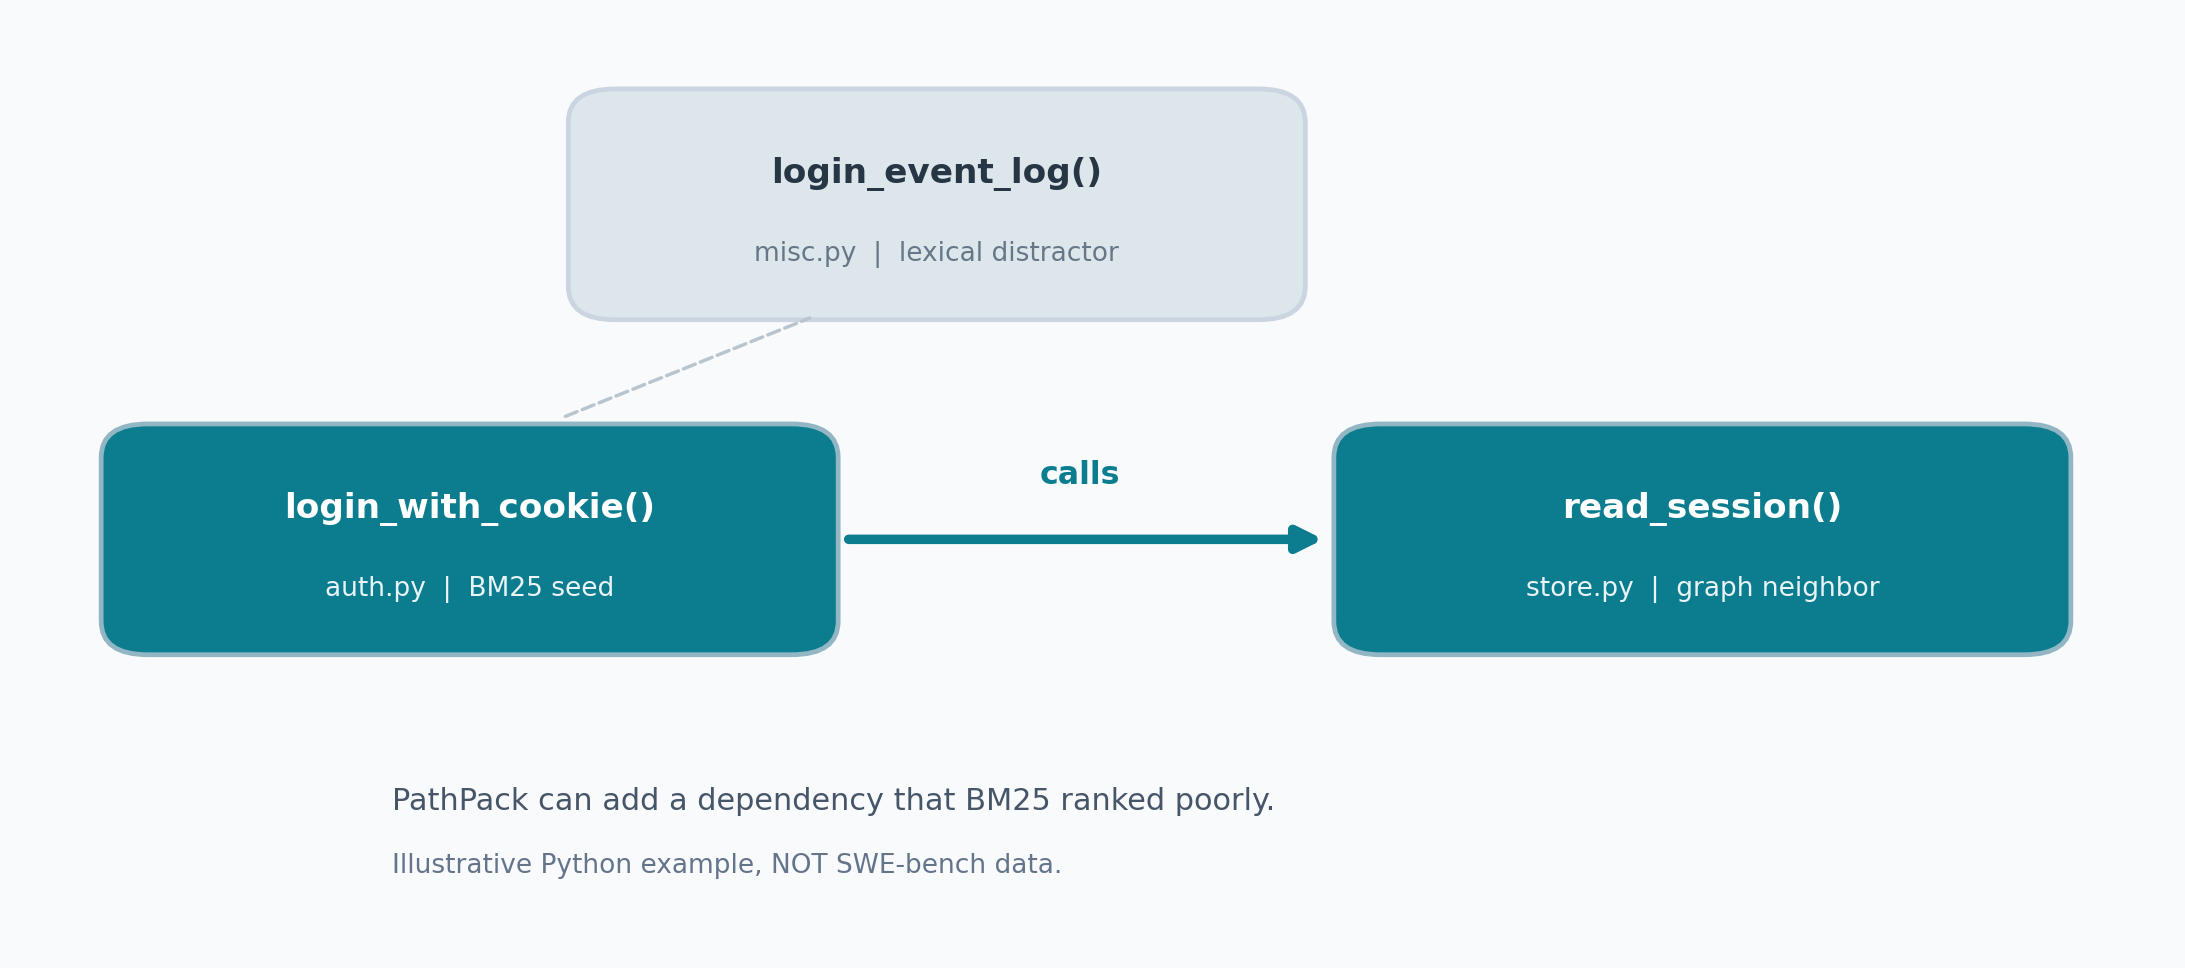

In [3]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / 'visualizations/pathpack_selected.png')))

## 3. BM25 против graph expansion и PathPack

Каждый метод получает одинаковый набор исходных файлов, один текст ошибки и одинаковый **приближённый** бюджет токенов. В v0.2 используется грубая оценка `ceil(байты UTF-8 / 4)`, **не** настоящий токенизатор Gemma 4.

Пути в графе помогают добираться до функций, которые не названы в тексте issue.

In [4]:
query = "Login cookie causes failure"
for method in ('bm25','graph-expand','pathpack'):
    graph, hits = retrieve(repo,query,method=method,budget=110,seeds=1,hops=2)
    print(method, '| tokens_est', sum(h.chunk.tokens_est for h in hits))
    for hit in hits:
        print('   ',hit.chunk.path, hit.chunk.qualname,'score',round(hit.score,3))
        print('      why:',hit.why[:150])

bm25 | tokens_est 70
    auth.py login_with_cookie score 5.902
      why: BM25 lexical match
    misc.py login_event_log score 2.85
      why: BM25 lexical match
graph-expand | tokens_est 82
    auth.py login_with_cookie score 6.902
      why: graph neighbor: auth.py::login_with_cookie
    store.py read_session score 3.182
      why: graph neighbor: auth.py::login_with_cookie > store.py::read_session
pathpack | tokens_est 82
    auth.py login_with_cookie score 1.0
      why: BM25 anchor seed
    store.py read_session score 1.12
      why: path: auth.py::login_with_cookie > store.py::read_session [calls]


## 4. Мини-эксперимент на 4 учебных сценариях

Описание четырёх задач, ожидаемые файлы и полный код генерации результатов хранятся в `examples/issue_demo/run_demo.py`. Включаем график именно для проверки пайплайна, а не для заявления об улучшении на реальном benchmark.

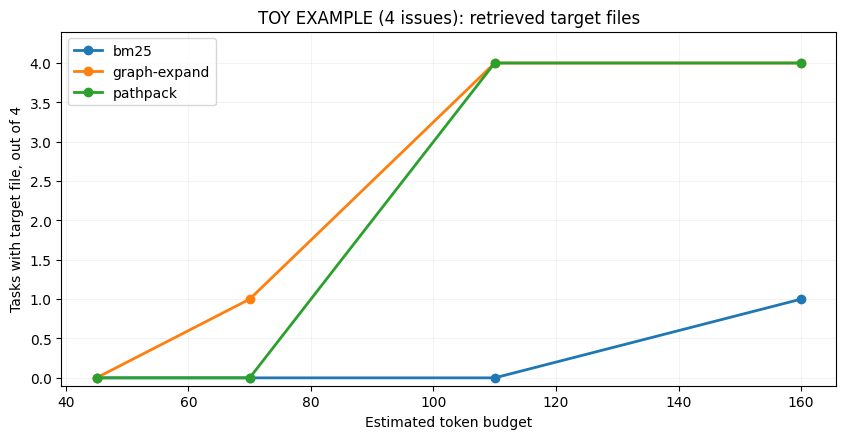

In [5]:
import matplotlib.pyplot as plt
from collections import defaultdict
results = json.loads((ROOT / 'reports/toy_results.json').read_text(encoding='utf8'))
budgets = sorted({r['budget_est'] for r in results})
methods = ['bm25','graph-expand','pathpack']
fig, ax = plt.subplots(figsize=(10,4.6))
for idx, method in enumerate(methods):
    v=[sum(r['hit'] for r in results if r['budget_est']==b and r['method']==method) for b in budgets]
    ax.plot(budgets,v,marker='o',label=method,linewidth=2)
ax.set(title='TOY EXAMPLE (4 issues): retrieved target files',xlabel='Estimated token budget',ylabel='Tasks with target file, out of 4',ylim=(-0.1,4.4))
ax.legend(); ax.grid(alpha=.15)
plt.show()

## 5. Факты, ограничения, следующие шаги

- Этот микронабор синтетический и создан вручную. На 110 условных токенах graph expansion и PathPack дают **одинаковый** результат, 4/4. Положительного преимущества PathPack пока **нет**.
- Часть module-level кода пропускается при построении чанков; динамическая семантика Python анализируется неполно.
- Реальный benchmark: сохранить `issues.jsonl` отдельно от `gold_labels.jsonl`; извлекать граф только из `base_commit`; использовать `codegraph retrieve-batch` и только затем `codegraph score`.
- Следующий эксперимент: минимум 5–10 настоящих задач в pilot, потом 80 задач, настройки только на `dev`.

Официальные источники: [SWE-bench Verified](https://huggingface.co/datasets/princeton-nlp/SWE-bench_Verified), [SWE-bench docs](https://github.com/SWE-bench/SWE-bench/blob/main/docs/guides/datasets.md), [GraphCoder](https://arxiv.org/abs/2406.07003).